In [3]:
import os, sys
os.environ["JAVA_HOME"] ="C:\\Users\\victorien.sauvonnet\\Desktop\\OpenJDK17U-jdk_x64_windows_hotspot_17.0.20.1_1\\jdk-17.0.20.1+1"
os.environ["PATH"]= os.environ["JAVA_HOME"] + "\\bin;" + os.environ["PATH"]
# Indispensable sous Windows : Spark doit utiliser le Python du venv
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("MushroomWorkshop")
    .master("local[*]")                 # tous les cœurs de la machine
    .config("spark.driver.memory", "2g")
    .config("spark.sql.shuffle.partitions", "8")  # petit dataset → peu de partitions
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN") # limite les messages de log à partir du niveau WARN

print(spark.version)
spark.range(5).show()

c:\Users\victorien.sauvonnet\Desktop\PYspark\mushrooms\mushenv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


4.2.0
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



In [5]:
from pyspark.sql import functions as F

df = spark.read.csv("./data/mushrooms.csv", header=True, inferSchema=False) # inferSchema=False pour que toutes les colonnes soient lues comme des chaînes de caractères
df = df.toDF(*[c.replace("-", "_") for c in df.columns]) # remplace les tirets par des underscores dans les noms de colonnes pour éviter les problèmes d'accès aux colonnes
                                                         # * permet de passer la liste des noms de colonnes comme arguments séparés à la fonction toDF()
df.printSchema()
print(df.count(), "lignes,", len(df.columns), "colonnes")   # 8124 lignes, 23 colonnes
df.show(5, truncate=False)

root
 |-- class: string (nullable = true)
 |-- cap_shape: string (nullable = true)
 |-- cap_surface: string (nullable = true)
 |-- cap_color: string (nullable = true)
 |-- bruises: string (nullable = true)
 |-- odor: string (nullable = true)
 |-- gill_attachment: string (nullable = true)
 |-- gill_spacing: string (nullable = true)
 |-- gill_size: string (nullable = true)
 |-- gill_color: string (nullable = true)
 |-- stalk_shape: string (nullable = true)
 |-- stalk_root: string (nullable = true)
 |-- stalk_surface_above_ring: string (nullable = true)
 |-- stalk_surface_below_ring: string (nullable = true)
 |-- stalk_color_above_ring: string (nullable = true)
 |-- stalk_color_below_ring: string (nullable = true)
 |-- veil_type: string (nullable = true)
 |-- veil_color: string (nullable = true)
 |-- ring_number: string (nullable = true)
 |-- ring_type: string (nullable = true)
 |-- spore_print_color: string (nullable = true)
 |-- population: string (nullable = true)
 |-- habitat: string 

In [7]:
df.groupBy("class").count().show()


+-----+-----+
|class|count|
+-----+-----+
|    p| 3916|
|    e| 4208|
+-----+-----+



In [ ]:
# compte des valeurs distinctes par colonne

df.select([F.countDistinct(c).alias(c) for c in df.columns]).show(vertical=True)

-RECORD 0-----------------------
 class                    | 2   
 cap_shape                | 6   
 cap_surface              | 4   
 cap_color                | 10  
 bruises                  | 2   
 odor                     | 9   
 gill_attachment          | 2   
 gill_spacing             | 2   
 gill_size                | 2   
 gill_color               | 12  
 stalk_shape              | 2   
 stalk_root               | 5   
 stalk_surface_above_ring | 4   
 stalk_surface_below_ring | 4   
 stalk_color_above_ring   | 9   
 stalk_color_below_ring   | 9   
 veil_type                | 1   
 veil_color               | 4   
 ring_number              | 3   
 ring_type                | 5   
 spore_print_color        | 9   
 population               | 6   
 habitat                  | 7   



In [ ]:
# compte des valeurs manquantes par colonne

df.select([F.sum((F.col(c) == "?").cast("int")).alias(c) for c in df.columns]).show(vertical=True) #cast("int") convertit le booléen en entier (True → 1, False → 0) pour pouvoir faire la somme

-RECORD 0------------------------
 class                    | 0    
 cap_shape                | 0    
 cap_surface              | 0    
 cap_color                | 0    
 bruises                  | 0    
 odor                     | 0    
 gill_attachment          | 0    
 gill_spacing             | 0    
 gill_size                | 0    
 gill_color               | 0    
 stalk_shape              | 0    
 stalk_root               | 2480 
 stalk_surface_above_ring | 0    
 stalk_surface_below_ring | 0    
 stalk_color_above_ring   | 0    
 stalk_color_below_ring   | 0    
 veil_type                | 0    
 veil_color               | 0    
 ring_number              | 0    
 ring_type                | 0    
 spore_print_color        | 0    
 population               | 0    
 habitat                  | 0    



In [ ]:
# crosstab : tableau croisé des valeurs de deux colonnes

df.crosstab("odor", "class").orderBy("odor_class").show()

+----------+----+----+
|odor_class|   e|   p|
+----------+----+----+
|         a| 400|   0|
|         c|   0| 192|
|         f|   0|2160|
|         l| 400|   0|
|         m|   0|  36|
|         n|3408| 120|
|         p|   0| 256|
|         s|   0| 576|
|         y|   0| 576|
+----------+----+----+



c:\Users\victorien.sauvonnet\Desktop\PYspark\mushrooms\mushenv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


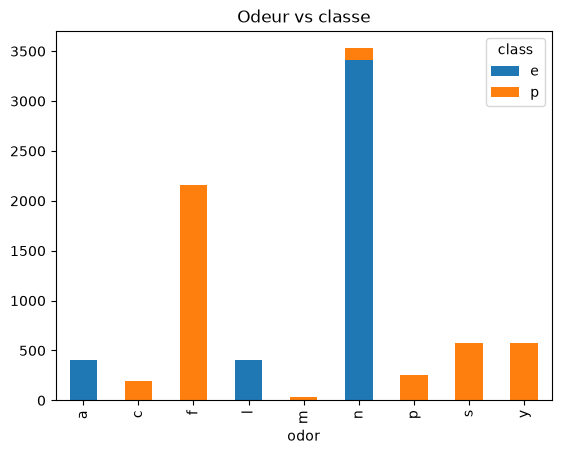

In [11]:
import matplotlib.pyplot as plt

pdf = df.groupBy("odor", "class").count().toPandas()
pdf.pivot(index="odor", columns="class", values="count").fillna(0).plot.bar(stacked=True)
plt.title("Odeur vs classe")
plt.show()

In [ ]:
#creation du pipeline de pretraitement des données

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

feature_cols = [c for c in df.columns if c not in ("class", "veil_type")] # class est la variable cible, veil_type est constante → inutile

label_indexer = StringIndexer(inputCol="class", outputCol="label") # stringindexer pour transformer la variable cible en numérique (e=0, p=1) et l'appeler "label" pour que le modèle puisse la reconnaître

indexer = StringIndexer(
    inputCols=feature_cols,
    outputCols=[f"{c}_idx" for c in feature_cols], # transforme les colonnes catégorielles en numériques (chaque modalité devient un entier) et les appelle "nom_colonne_idx"
    handleInvalid="keep",          # modalité inconnue en test → pas de plantage
)

encoder = OneHotEncoder(
    inputCols=[f"{c}_idx" for c in feature_cols],
    outputCols=[f"{c}_ohe" for c in feature_cols],
    handleInvalid="keep",
) # OneHotEncoder pour transformer les colonnes numériques en vecteurs binaires (une colonne par modalité) et les appeler "nom_colonne_ohe"

assembler = VectorAssembler(
    inputCols=[f"{c}_ohe" for c in feature_cols],
    outputCol="features",
) # VectorAssembler pour assembler toutes les colonnes binaires en un seul vecteur de caractéristiques appelé "features"

prep_stages = [label_indexer, indexer, encoder, assembler]

In [ ]:
prep_model = Pipeline(stages=prep_stages).fit(df) # fit df pour créer un modèle de pipeline qui contient les étapes d'indexation, d'encodage et d'assemblage des colonnes
prep_df = prep_model.transform(df) # transforme le dataframe df en appliquant les étapes du pipeline (indexation, encodage, assemblage) et crée un nouveau dataframe prep_df avec les colonnes "label" et "features"
prep_df.select("class", "label", "features").show(5, truncate=False)
print(prep_model.stages[0].labels)   # ['e', 'p'] → 0 = comestible, 1 = vénéneux

+-----+-----+---------------------------------------------------------------------------------------------------------------------------------------------------------------+
|class|label|features                                                                                                                                                       |
+-----+-----+---------------------------------------------------------------------------------------------------------------------------------------------------------------+
|p    |1.0  |(137,[0,8,12,24,32,36,39,43,52,59,63,67,72,77,87,97,102,106,114,124,133],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|
|e    |0.0  |(137,[0,8,15,24,30,36,39,42,52,59,64,67,72,77,87,97,102,106,113,125,130],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|
|e    |0.0  |(137,[3,8,16,24,31,36,39,42,48,59,64,67,72,77,87,97,102,106,113,125,134],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0

In [ ]:
# split train/test

train, test = df.randomSplit([0.8, 0.2], seed=42)
train.cache(); test.cache() # cache pour éviter de relire les données à chaque action
print(train.count(), test.count())

6573 1551


In [15]:
from pyspark.ml.classification import (
    LogisticRegression, DecisionTreeClassifier, RandomForestClassifier,
    GBTClassifier, NaiveBayes,
)
from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator, BinaryClassificationEvaluator,
)

models = {
    "LogisticRegression": LogisticRegression(maxIter=50),
    "DecisionTree":       DecisionTreeClassifier(maxDepth=5, seed=42),
    "RandomForest":       RandomForestClassifier(numTrees=50, maxDepth=5, seed=42),
    "GBT":                GBTClassifier(maxIter=20, maxDepth=3, seed=42),
    "NaiveBayes":         NaiveBayes(),   # OK : features one-hot ≥ 0
}

acc_eval = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy")
f1_eval  = MulticlassClassificationEvaluator(labelCol="label", metricName="f1")
auc_eval = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")

results, fitted = [], {}
for name, clf in models.items():
    model = Pipeline(stages=prep_stages + [clf]).fit(train) # fit le pipeline complet (prétraitement + modèle) sur le jeu d'entraînement
    pred = model.transform(test) # .transform le jeu de test pour obtenir les prédictions
    fitted[name] = model
    results.append((name, acc_eval.evaluate(pred), f1_eval.evaluate(pred), auc_eval.evaluate(pred)))

spark.createDataFrame(results, ["modele", "accuracy", "f1", "auc"]) \
     .orderBy(F.desc("accuracy")).show()

+------------------+------------------+------------------+------------------+
|            modele|          accuracy|                f1|               auc|
+------------------+------------------+------------------+------------------+
|LogisticRegression|               1.0|               1.0|               1.0|
|               GBT|0.9993552546744036|0.9993552477039664|0.9993180805130695|
|      RandomForest|0.9929078014184397|0.9929066333009845|0.9999185023052205|
|      DecisionTree|0.9929078014184397|0.9929079960389535|0.9890094537325945|
|        NaiveBayes|0.9484203739522888|0.9482626511288372| 0.956536780408618|
+------------------+------------------+------------------+------------------+



In [ ]:
pred = fitted["DecisionTree"].transform(test) # fitted["DecisionTree"] est le modèle de pipeline complet (prétraitement + modèle) qui a été entraîné sur le jeu d'entraînement. On utilise ce modèle pour transformer le jeu de test et obtenir les prédictions.
pred.groupBy("label", "prediction").count().orderBy("label", "prediction").show()

faux_comestibles = pred.filter((F.col("label") == 1) & (F.col("prediction") == 0)).count()
print("Vénéneux prédits comestibles :", faux_comestibles)

+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0|  781|
|  0.0|       1.0|    7|
|  1.0|       0.0|    4|
|  1.0|       1.0|  759|
+-----+----------+-----+

Vénéneux prédits comestibles : 4


In [18]:
pred2 = fitted["LogisticRegression"].transform(test)

[[788   0]
 [  0 763]]


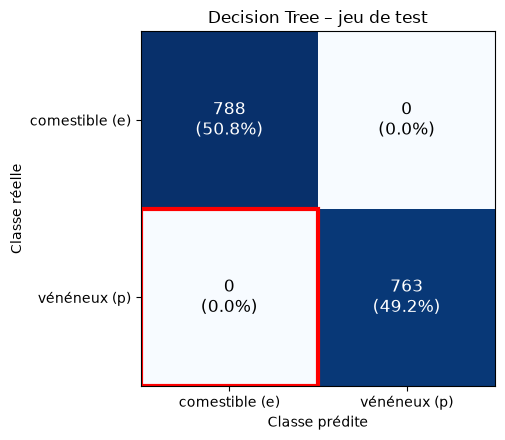

In [19]:
import numpy as np
import matplotlib.pyplot as plt

def matrice_confusion(pred, labels=("comestible (e)", "vénéneux (p)")):
    """Calcule la matrice de confusion dans Spark et la renvoie en numpy (lignes = réel, colonnes = prédit)."""
    counts = pred2.groupBy("label", "prediction").count().collect()
    n = len(labels)
    cm = np.zeros((n, n), dtype=int)
    for r in counts:
        cm[int(r["label"]), int(r["prediction"])] = r["count"]
    return cm

def afficher_matrice(cm, labels=("comestible (e)", "vénéneux (p)"), titre="Matrice de confusion", ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.5))
    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
    ax.set_title(titre)

    # Valeurs + % dans chaque case (texte blanc sur les cases foncées)
    total = cm.sum()
    seuil = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / total:.1%})",
                    ha="center", va="center",
                    color="white" if cm[i, j] > seuil else "black", fontsize=12)

    # Encadre en rouge l'erreur dangereuse : vénéneux prédit comestible
    ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor="red", linewidth=3))
    return ax

# --- Utilisation ---
pred = fitted["DecisionTree"].transform(test)
cm = matrice_confusion(pred)
print(cm)

afficher_matrice(cm, titre="Decision Tree – jeu de test")
plt.tight_layout()
plt.show()

In [ ]:
#utilisation de CrossValidator pour la DecisionTree

from pyspark.ml.tuning import ParamGridBuilder, CrossValidator, TrainValidationSplit

dt = DecisionTreeClassifier(labelCol="label", featuresCol="features", seed=42)
pipeline = Pipeline(stages=prep_stages + [dt])

grid = (ParamGridBuilder()
        .addGrid(dt.maxDepth, [1, 2, 3, 5, 8])
        .addGrid(dt.impurity, ["gini", "entropy"])
        .build())                     # 5 × 2 = 10 combinaisons

cv = CrossValidator(
    estimator=pipeline,
    estimatorParamMaps=grid,
    evaluator=acc_eval,
    numFolds=3,                       # 10 combinaisons × 3 folds = 30 entraînements
    parallelism=2,
    seed=42,
)
cv_model = cv.fit(train)

# Score moyen de chaque combinaison
for params, score in zip(grid, cv_model.avgMetrics):
    print({p.name: v for p, v in params.items()}, round(score, 4))

best_dt = cv_model.bestModel.stages[-1]
print("Meilleur maxDepth :", best_dt.getOrDefault("maxDepth"),
      "| impurity :", best_dt.getOrDefault("impurity"))
print("Accuracy test :", acc_eval.evaluate(cv_model.transform(test)))

{'maxDepth': 1, 'impurity': 'gini'} 0.8879
{'maxDepth': 1, 'impurity': 'entropy'} 0.8879
{'maxDepth': 2, 'impurity': 'gini'} 0.9546
{'maxDepth': 2, 'impurity': 'entropy'} 0.9283
{'maxDepth': 3, 'impurity': 'gini'} 0.9858
{'maxDepth': 3, 'impurity': 'entropy'} 0.962
{'maxDepth': 5, 'impurity': 'gini'} 0.997
{'maxDepth': 5, 'impurity': 'entropy'} 0.9995
{'maxDepth': 8, 'impurity': 'gini'} 0.9997
{'maxDepth': 8, 'impurity': 'entropy'} 0.9997
Meilleur maxDepth : 8 | impurity : gini
Accuracy test : 0.9993552546744036


In [ ]:
# utilisation de TrainValidationSplit pour la régression logistique

lr = LogisticRegression(labelCol="label", featuresCol="features")
pipeline_lr = Pipeline(stages=prep_stages + [lr])

grid_lr = (ParamGridBuilder()
           .addGrid(lr.regParam, [0.0, 0.01, 0.1, 1.0])
           .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])   # 0 = L2 (Ridge), 1 = L1 (Lasso)
           .addGrid(lr.maxIter, [20, 50])
           .build())

tvs = TrainValidationSplit(
    estimator=pipeline_lr,
    estimatorParamMaps=grid_lr,
    evaluator=auc_eval,
    trainRatio=0.8,
    parallelism=2,
    seed=42,
)
tvs_model = tvs.fit(train)

best_lr = tvs_model.bestModel.stages[-1] # stages[-1] est le dernier stage du pipeline, c'est-à-dire le modèle de régression logistique entraîné avec les meilleurs hyperparamètres trouvés par TrainValidationSplit les tage precedent sont les etape de pretraitment
print("regParam :", best_lr.getRegParam(), "| elasticNet :", best_lr.getElasticNetParam())
print("AUC test :", auc_eval.evaluate(tvs_model.transform(test)))

regParam : 0.01 | elasticNet : 0.0
AUC test : 0.9999883574721744


In [22]:
print(best_dt.toDebugString)

DecisionTreeClassificationModel: uid=DecisionTreeClassifier_96ac371ec73b, depth=7, numNodes=29, numClasses=2, numFeatures=137
  If (feature 26 in {1.0})
   If (feature 116 in {0.0})
    If (feature 95 in {0.0})
     If (feature 10 in {1.0})
      Predict: 1.0
     Else (feature 10 not in {1.0})
      If (feature 15 in {1.0})
       Predict: 1.0
      Else (feature 15 not in {1.0})
       If (feature 75 in {0.0})
        If (feature 5 in {1.0})
         Predict: 1.0
        Else (feature 5 not in {1.0})
         Predict: 0.0
       Else (feature 75 not in {0.0})
        If (feature 42 in {1.0})
         Predict: 0.0
        Else (feature 42 not in {1.0})
         Predict: 1.0
    Else (feature 95 not in {0.0})
     Predict: 1.0
   Else (feature 116 not in {0.0})
    Predict: 1.0
  Else (feature 26 not in {1.0})
   If (feature 64 in {1.0})
    If (feature 23 in {0.0})
     Predict: 0.0
    Else (feature 23 not in {0.0})
     Predict: 1.0
   Else (feature 64 not in {1.0})
    If (feature 

In [ ]:
#calcul des importances des variables pour le RandomForest

from itertools import chain

rf_model = fitted["RandomForest"] # fitted fait référence au dictionnaire contenant les modèles entraînés pour chaque algorithme. Ici, on récupère le modèle RandomForest entraîné à partir du pipeline complet (prétraitement + modèle) qui a été ajusté sur le jeu d'entraînement.
pred_rf = rf_model.transform(test)

meta = pred_rf.schema["features"].metadata["ml_attr"]["attrs"]
names = {a["idx"]: a["name"] for a in chain(*meta.values())}
importances = rf_model.stages[-1].featureImportances.toArray()

top = sorted(((names[i], float(v)) for i, v in enumerate(importances)),
             key=lambda x: -x[1])[:10]
for name, imp in top:
    print(f"{name:35s} {imp:.3f}")

odor_ohe_n                          0.151
gill_size_ohe_n                     0.100
spore_print_color_ohe_h             0.092
odor_ohe_f                          0.073
gill_size_ohe_b                     0.059
stalk_surface_above_ring_ohe_k      0.056
ring_type_ohe_p                     0.043
stalk_surface_above_ring_ohe_s      0.037
gill_color_ohe_b                    0.032
bruises_ohe_t                       0.032


In [24]:
from pyspark.ml import PipelineModel

cv_model.bestModel.write().overwrite().save("../models/mushroom_dt")

loaded = PipelineModel.load("../models/mushroom_dt")

Py4JJavaError: An error occurred while calling o39969.save.
: java.lang.RuntimeException: java.io.FileNotFoundException: java.io.FileNotFoundException: HADOOP_HOME and hadoop.home.dir are unset. -see https://cwiki.apache.org/confluence/display/HADOOP2/WindowsProblems
	at org.apache.hadoop.util.Shell.getWinUtilsPath(Shell.java:790)
	at org.apache.hadoop.util.Shell.getSetPermissionCommand(Shell.java:299)
	at org.apache.hadoop.util.Shell.getSetPermissionCommand(Shell.java:315)
	at org.apache.hadoop.fs.RawLocalFileSystem.setPermission(RawLocalFileSystem.java:1179)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkOneDirWithMode(RawLocalFileSystem.java:861)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirsWithOptionalPermission(RawLocalFileSystem.java:901)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirs(RawLocalFileSystem.java:873)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirsWithOptionalPermission(RawLocalFileSystem.java:900)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirs

In [25]:
nouveau = spark.createDataFrame([{
    "class": "e",   # valeur factice, requise par l'indexeur de label
    "cap_shape": "x", "cap_surface": "s", "cap_color": "n", "bruises": "t",
    "odor": "p", "gill_attachment": "f", "gill_spacing": "c", "gill_size": "n",
    "gill_color": "k", "stalk_shape": "e", "stalk_root": "e",
    "stalk_surface_above_ring": "s", "stalk_surface_below_ring": "s",
    "stalk_color_above_ring": "w", "stalk_color_below_ring": "w",
    "veil_type": "p", "veil_color": "w", "ring_number": "o", "ring_type": "p",
    "spore_print_color": "k", "population": "s", "habitat": "u",
}])

loaded.transform(nouveau).select("odor", "probability", "prediction").show(truncate=False)
# prediction = 1.0 → vénéneux (odeur âcre)

NameError: name 'loaded' is not defined

In [26]:
print(spark.sparkContext._jvm.org.apache.hadoop.util.VersionInfo.getVersion())
# ex. 3.4.1 ou 3.3.4

3.5.0
